# Session 10: Open the black box

**Week 5 · Session 2 · LangGraph I of III · Project version v7**

Since session 5 every ShopWise answer has come out of `create_agent`, and the agent has chosen its own
steps. Tonight you open it, build the thing it is made of, and use that to fix three failures v6
cannot fix by prompting.

<img src="figures/session-map.png" width="900"
     alt="The whole of session 10 on one page. Across the top, v6 is one agent that chooses its own
     steps, and v7 is an inbox graph whose order is in the edges. Below, two zones. Zone A, the graph
     model: agent or workflow, state with reducers, nodes and edges, conditional edges and Command,
     and the agent loop built by hand. Zone B, the five workflow patterns: chaining with a gate,
     routing to scoped desks, RAG-Fusion as parallel fan-out, orchestrator-worker with Send, and
     corrective RAG as evaluator-optimizer. A bottom band says a step that must always happen belongs
     in an edge, not in a prompt.">

There are two main topics:

| | Topic | Question it answers |
|---|---|---|
| **A** | **The graph model** | What is an agent actually made of, and who chooses the next step? |
| **B** | **Five workflow patterns** | Which shapes do production AI workflows take, and when does each one fit? |

Two of B's five patterns are retrieval techniques you will meet in every RAG job description:
**RAG-Fusion** is parallel fan-out, and **corrective RAG** is evaluator-optimizer. Each one costs model
calls on every question, so section 16 measures whether either earns its place on ShopWise.

By the end you will have **v7**: a `workflows/inbox/` graph that answers inbound tickets. Triage runs
once, `split` breaks the ticket into sub-issues, `Send` hands each one to a desk with its own tools,
and `compose` writes one reply. `chat.py` is untouched, and section 17 explains why.

## 1. Setup

Nothing new to install: `langgraph` came with `langchain` in session 4, and you have been running it
ever since without importing it. The knowledge base is session 8's, in `labs/.state/qdrant/`.

The v7 project adds two folders and three files, and the notebook imports their real functions:

| Module | What it does |
|---|---|
| `workflows/inbox/` | **new**: the inbox graph: `state.py`, `nodes.py`, `graph.py`, `diagram.md` |
| `workflows/corrective_rag/` | **new**: the policy desk's graph: search, grade, answer |
| `kb/fusion.py` | **new**: RAG-Fusion and HyDE as graph nodes, plus reciprocal-rank fusion |
| `inbox.py` | **new**: `uv run python inbox.py TCK-M01`, one ticket in, one reply out |
| `evals/run_eval.py` | gains a `graph` target and a calls-per-question column |

**Two providers, as in sessions 8 and 9.** Answers come from `openrouter:openai/gpt-oss-20b`; every
search embeds with Gemini's `gemini-embedding-2`. **This notebook makes a lot of model calls**, roughly
150 for the lesson cells and about 250 more for section 16's scorecard, which has a `LIMIT` you can
lower. The committed outputs show what you would have seen.

**Docs:** [LangGraph overview](https://docs.langchain.com/oss/python/langgraph/overview)

In [2]:
import json
import operator
import subprocess
import sys
import time
import warnings
from pathlib import Path
from typing import Annotated, Literal, TypedDict

import yaml
from langchain_core._api import LangChainBetaWarning

warnings.filterwarnings("ignore", category=LangChainBetaWarning)
warnings.filterwarnings("ignore", message="IProgress not found")    # fastembed's progress bar

HERE = Path.cwd()
sys.path.insert(0, str(HERE / "project"))        # the v7 snapshot beside this notebook

from langgraph.checkpoint.memory import InMemorySaver    # noqa: E402
from langgraph.graph import END, START, StateGraph       # noqa: E402

from config import settings                      # noqa: E402
from kb import rag, store                        # noqa: E402
from middleware import customer_for              # noqa: E402
from utils import build_model                    # noqa: E402

model = build_model()
points = store.shared_client().count(settings.collection).count
print(f"{settings.APP_NAME} v{settings.VERSION} · {settings.model_id}")
print(f"knowledge base: {settings.collection} · {points} chunks")
print(f"retrieval switches: fusion={settings.RAG_FUSION} hyde={settings.RAG_HYDE} "
      f"grade={settings.RAG_GRADE} (max {settings.RAG_MAX_ATTEMPTS} searches)")
assert points, "Empty knowledge base: run `uv run python kb/ingest.py` from project/ first."

ShopWise Support Assistant v7.0.0 · openrouter:openai/gpt-oss-20b
knowledge base: policies__gemini-embedding-2-768 · 70 chunks
retrieval switches: fusion=False hyde=False grade=False (max 2 searches)


Three helpers. `show` prints one definition straight from a project file, so you read the code that
actually runs. `tool_path` lists the tools an agent run called, in order. `draw` shows a graph as a picture.

In [3]:
from IPython.display import Image, display    # noqa: E402


def show(name, file):
    """Print one top-level definition from a project file: the real code, not a copy."""
    lines = (HERE / "project" / file).read_text().splitlines()
    start = next(i for i, l in enumerate(lines)
                 if l.startswith((f"def {name}(", f"{name} = ", f"class {name}(")))
    while lines[start - 1].startswith("@"):
        start -= 1
    end = start + 1
    while end < len(lines) and (not lines[end] or lines[end][0] in " )]}"):
        end += 1
    print("\n".join(lines[start:end]).rstrip())


def tool_path(result):
    """The tools an agent run called, in order."""
    return [call["name"] for m in result["messages"] if m.type == "ai" for call in m.tool_calls]


def draw(graph):
    """Show a compiled graph as a picture in the output cell.

    draw_mermaid_png() sends the diagram text to the mermaid.ink web service to
    render it (free, no key, not a model call), so it needs internet. Offline, the
    same diagram is printed as mermaid text instead."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception as err:
        print(f"(could not render the picture offline: {type(err).__name__}; here is the text)")
        print(graph.get_graph().draw_mermaid().split("---")[-1])


## 2. The failures: three things a prompt cannot guarantee

Session 9 ended with v6 answering from the knowledge base, with citations, and a scorecard to prove
it. Three things are still left to the model's judgement, one for each part of tonight.

**Failure 1: a rule without its facts.** *"Can I still return the backpack from ORD-5004?"* needs two
things: the rule (30 days from delivery) and the order's delivery date. v6's agent has both tools and
a prompt line telling it to look the order up when a rule depends on a date. Ask it three times.
`agent.py` is v6's agent, unchanged in this snapshot.

In [16]:
from agent import answer, build_agent    # noqa: E402

v6 = build_agent(InMemorySaver())
priya = customer_for("priya@example.com")
RETURN_Q = "Can I still return the backpack from ORD-5004?"

for run in (1, 2, 3):
    result = answer(v6, RETURN_Q, f"S10-OPEN-{run}", priya)
    print(f"run {run}: {' → '.join(tool_path(result)) or '(no tools)'}")
    print(f"       {result['messages'][-1].text[:300]}\n")

run 1: get_order → search_policy
       Your order was delivered on 2026‑05‑07. According to our return policy, most items—including backpacks—can be returned within **30 days of the delivery date**. That window closed on 2026‑06‑06, so the backpack is no longer eligible for a return. [returns-policy · 1. The return window]

run 2: get_order → search_policy
       Your order was delivered on 7 May 2026. According to our return policy, most items can be returned within 30 days of delivery. That window closed on 6 June 2026, so the backpack is outside the return period. If you have any other questions or need assistance, let me know.

run 3: get_order → search_policy
       Your order was delivered on 7 May 2026. According to our return policy, most items can be returned within 30 days of delivery. That window closed on 6 June 2026, so the backpack is outside the return period. If you have any other questions or need assistance, let me know.



<!-- revise after execution: name what each run actually did -->
Read the three tool paths before the answers. The question is whether **every** run called `get_order`
before ruling on the return. ORD-5004 was delivered on 7 May, so any answer that does not mention a
date it looked up is applying a correct rule to a date it never checked.

If all three runs looked the order up this time, that is not reassurance. v6 *usually* chooses to
look, and "usually" is exactly the problem. A step that must always happen is being enforced by
probability. Run the cell again and count. Tonight that step becomes an **edge**.

**Failure 2: four problems, one context.** Customers write tickets about several things at once, so
v7 adds a fixture of them, `data/multi_issue_tickets.yml`. They live apart from `tickets.yml`: those
twenty each carry one hand-labelled category and score triage, and a ticket about four things has no
single right label.

TCK-M04 asks four questions about four different things:

In [17]:
MULTI = {t["id"]: t for t in yaml.safe_load((settings.DATA_DIR / "multi_issue_tickets.yml").read_text())}
m04 = MULTI["TCK-M04"]
print(m04["body"], "\n")

tanvir = customer_for(m04["from"])
for run in (1, 2):
    result = answer(v6, m04["body"], f"S10-M04-{run}", tanvir)
    print(f"run {run}: {' → '.join(tool_path(result))}")
    print(result["messages"][-1].text, "\n")

Four quick ones. The tracking for ORD-5003 has been stuck for three days, is the parcel lost? How long is the warranty on the PulseFit smartwatch? Is the BrewMaster kettle back in stock, I want to buy one as a gift. And my card statement shows two charges of $199 for ORD-5003, can you check? 

run 1: get_shipment → get_product → get_product → get_order
The shipment for ORD‑5003 is in transit and the tracking ID is SW‑88231.  
The PulseFit Smartwatch comes with a 24‑month warranty.  
The BrewMaster Electric Kettle is currently out of stock.  
ORD‑5003’s total is $199.00, so the two $199 charges on your statement are likely a duplicate; I’ll forward this to our billing team for review. 

run 2: get_shipment → get_product → get_product
I'm not able to answer that one myself. I've passed your message to a member of the ShopWise team, who will reply to you directly. 



In [18]:
from tools import get_product    # noqa: E402

kettle = get_product.invoke({"sku_or_name": "BrewMaster kettle"})
print(f"what the record says: {kettle['name']} · stock {kettle['stock']}")

what the record says: BrewMaster Electric Kettle · stock 0


<!-- revise after execution: quote the wrong sentence, if one appeared -->
Check each of the four answers against the records, not against how it reads. The kettle (SKU-300)
has `stock: 0`. ORD-5003 shows one charge of $199, and the agent has no tool that can see card
statements at all. The usual failure is not a forgotten issue. It is a **confident wrong** answer to
one of them: "the kettle is in stock", or a citation label that names no real source. A wrong
sentence that sits between three right ones is exactly where nobody checks.

Two causes. One loop is doing four jobs in one context with one tool budget, so a miss on one
issue doesn't get retried. And `get_product` itself misled it. Until v6 it matched the whole query as
one substring, so "BrewMaster kettle" found nothing (the catalogue says "BrewMaster *Electric*
Kettle"). Its no-match list was then called `available`, and a model read that as "in stock". v7's
`tools.py` fixes both: every *word* must appear in the name, and the list is now called `catalogue`.
The cell above uses the fixed tool. **A tool's error message is a prompt too, and the model believes
its key names.**

Tonight's fix gives each issue its own desk, its own context and its own budget.

**Failure 3: retrieval that missed, and nobody noticed.** Two questions session 9's scorecard found
hard. The first has a vocabulary mismatch: the customer says "money back for a gift", the policy says
"gift cards" and "non-returnable". The second is underspecified: which watch, what kind of fault?

In [19]:
GIFT = "Can I get my money back for a gift?"
WATCH = "What's the warranty for the watch?"

for question in (GIFT, WATCH):
    result = rag.answer_with_rag(question)
    print(f"Q: {question}")
    for d in result["documents"]:
        print(f"   retrieved {rag.label(d)}")
    print(f"A: {result['answer']}\n")

Q: Can I get my money back for a gift?
   retrieved [returns-policy · 2. What cannot be returned]
   retrieved [returns-policy · 1. The return window]
   retrieved [returns-policy · 3. How refunds are paid]
   retrieved [returns-policy · 4. Starting a return]
A: No – gift cards and store credit are final sale and cannot be refunded [returns-policy · 2.1].

Q: What's the warranty for the watch?
   retrieved [warranty-policy · 1. What the warranty covers]
   retrieved [warranty-policy · 2. How long each product type is covered]
   retrieved [warranty-policy · 3. Making a claim]
   retrieved [warranty-policy · preamble]
A: The watch is a wearable, so it comes with a 24‑month limited warranty that starts on the delivery date and covers faults in materials or workmanship that appear in normal use. Accidental damage, misuse, normal wear, cosmetic marks and unauthorised repair are not covered. [warranty-policy · 2] [warranty-policy · 1]



<!-- revise after execution: say which passages came back and whether it refused -->
Look at the retrieved labels before the answer. If the passage that holds the rule is not among them,
`generate` can only do one of two things. It can refuse (the grounding contract working, but on a
question the corpus *can* answer), or it can build an answer from near-misses. Either way, nothing
between `retrieve` and `generate` asks the obvious question: *are these passages any good?*

Three failures, one shape. Something that should happen every time, or should be checked every time,
is left to a single model call's judgement. LangGraph is how you take it back.

## 3. Where we are on the map

| | v6 (session 9) | v7 (tonight) |
|---|---|---|
| Who picks the steps | the model, every run | the graph's edges, plus small agents inside some nodes |
| A return question | the agent may or may not look the order up | the order's facts are fetched in code, always |
| One ticket, four issues | one context, one tool budget | one desk per issue, each with its own tools |
| Weak retrieval | goes straight to the answer | fused, graded and retried, if the scorecard says it pays |
| `create_agent` | a black box | a graph you can draw |

---
# Part A: The graph model

## 4. Workflow or agent: who chooses the next step?

That question is the whole distinction. In a **workflow**, your code chooses the next step, so the
order is guaranteed. In an **agent**, the model chooses, so the steps can fit the input, and they can
also vary when they shouldn't. Neither is better. They answer different problems, and most real
systems use both.

<img src="figures/spectrum.png" width="900"
     alt="Workflow or agent: who chooses the next step. A horizontal spectrum runs from workflow, where
     code chooses and the order is guaranteed, to agent, where the model chooses and the steps vary.
     Four ShopWise features sit on it: the daily brief and ticket triage at the workflow end, the
     inbox graph in the middle as a workflow with agents inside its nodes, and the chat assistant at
     the agent end. Below, a decision strip: same steps every time, or a step that must never be
     skipped, means workflow; steps that depend on the input mean agent.">

| If the process… | Choose | ShopWise example |
|---|---|---|
| has the same steps every time | workflow | the daily report |
| has a step that must never be skipped (compliance, audit, money) | workflow, at least around that step | look up the order before ruling on a return |
| has steps that depend on what the user says | agent | an open-ended chat |
| is a fixed process with an open-ended part inside it | workflow with agents in its nodes | tonight's inbox graph |

Anthropic's engineering team draws the same line: workflows run on "predefined code paths", agents
"dynamically direct their own processes and tool usage" ([Building effective
agents](https://www.anthropic.com/engineering/building-effective-agents), which also names tonight's
five patterns).

Now the reveal. v6's agent has been a LangGraph graph since session 5:

In [ ]:
print(type(v6).__name__)
for node in v6.get_graph().nodes:
    print("  ", node)

CompiledStateGraph
   __start__
   model
   tools
   content_filter.before_agent
   PIIMiddleware[credit_card].before_model
   PIIMiddleware[credit_card].after_model
   PIIMiddleware[email].before_model
   PIIMiddleware[email].after_model
   ModelCallLimitMiddleware.before_model
   ModelCallLimitMiddleware.after_model
   ToolCallLimitMiddleware.after_model
   SummarizationMiddleware.before_model
   blocked_reply.after_model
   HumanInTheLoopMiddleware.after_model
   __end__


: 

`create_agent` returned a `CompiledStateGraph`. Its two working nodes are `model` and `tools`. Every
other node is one of **your** session 7 rails: the content filter, the PII rules, the call limits and
the refund approval are all nodes, wired around the loop. Middleware was graph nodes all along. By
section 9 you will have built the `model ⇄ tools` loop yourself.

**Docs:** [Workflows and agents](https://docs.langchain.com/oss/python/langgraph/workflows-agents)

## 5. Thinking in graphs: five steps before any code

LangGraph's own design method has five steps, and they happen on a whiteboard first. Here they are,
done for the inbox:

| Step | Question | For the inbox |
|---|---|---|
| 1. Map the steps | What happens, in order? | receive → triage → split → answer each issue → write one reply |
| 2. Classify each step | LLM, data lookup, action, or human? | triage, split, compose: LLM · desks: LLM with lookups · no actions, no human (yet) |
| 3. Design the state | What must be remembered between steps? | the ticket, the triage, the sub-issues, each desk's finding, the reply |
| 4. Write nodes as plain functions | state in, updates out | one function per step |
| 5. Wire the edges | fixed, conditional, or fan-out? | fixed, except split → desks: one per sub-issue |

The state rule that matters most: **store raw data, not formatted prompt text.** Compare:

| Stored in state | What happens next |
|---|---|
| `"findings": "Issue 1: the order ORD-5002 is processing..."` | every later node has to parse a sentence back into facts, and changing the wording breaks it |
| `"findings": [{"position": 0, "desk": "orders", "note": "..."}]` | each node formats what it needs, when it needs it |

Formatting happens inside the node that sends text to a model, and nowhere else. In v7, `compose` is
the only node that turns findings into prose.

**Docs:** [Thinking in LangGraph](https://docs.langchain.com/oss/python/langgraph/thinking-in-langgraph)

## 6. State and reducers

A graph's state is a `TypedDict`: a dict with declared keys, nothing more exotic. A node receives the
whole state and returns **only the keys it changed**. LangGraph merges the return into the state, and
the default merge is *overwrite*.

That default breaks the moment two nodes write the same key in the same step. Two lookups run side
by side, both appending a note. No model is involved.

**This cell is meant to fail.** The error it prints is the point; the next cell fixes it.

In [15]:
class Notes(TypedDict):
    ticket: str
    notes: list[str]


def look_up_order(state: Notes) -> dict:
    return {"notes": ["order looked up"]}


def look_up_shipment(state: Notes) -> dict:
    return {"notes": ["shipment looked up"]}


builder = StateGraph(Notes)
builder.add_node("order", look_up_order)
builder.add_node("shipment", look_up_shipment)
builder.add_edge(START, "order")             # two edges out of START:
builder.add_edge(START, "shipment")          # both nodes run in the same step
builder.add_edge("order", END)
builder.add_edge("shipment", END)

# Expected to fail: two nodes write `notes` in the same step, and the key has no reducer.
try:
    builder.compile().invoke({"ticket": "TCK-001", "notes": []})
except Exception as err:
    print("Crashed, as expected:")
    print(f"  {type(err).__name__}: {str(err).splitlines()[0]}")

## Start -> {"ticket": "TCK-001", "notes": []}
## order -> {"ticket": "TCK-001", "notes": ["order looked up"]}
## shipment -> {"ticket": "TCK-001", "notes": ["shipment looked up"]}
## END -> {"ticket": "TCK-001", "notes": [?]}

Crashed, as expected:
  InvalidUpdateError: At key 'notes': Can receive only one value per step. Use an Annotated key to handle multiple values.


"Can receive only one value per step." LangGraph will not guess whether you wanted the first write,
the second, or both. You tell it with a **reducer**: a function attached to the key's type that says
how to combine a new value with the old one.

In [16]:
class Notes(TypedDict):
    ticket: str
    notes: Annotated[list[str], operator.add]     # combine by appending


builder = StateGraph(Notes)
builder.add_node("order", look_up_order)
builder.add_node("shipment", look_up_shipment)
builder.add_edge(START, "order")
builder.add_edge(START, "shipment")
builder.add_edge("order", END)
builder.add_edge("shipment", END)

builder.compile().invoke({"ticket": "TCK-001", "notes": []})

{'ticket': 'TCK-001', 'notes': ['order looked up', 'shipment looked up']}

In [18]:
g = builder.compile()

In [19]:
for update in g.stream({"ticket": "TCK-001", "notes": []}, stream_mode="updates"):
    print(update)

{'order': {'notes': ['order looked up']}}
{'shipment': {'notes': ['shipment looked up']}}


<img src="figures/state-reducers.png" width="900"
     alt="Graph state and reducers. A node receives the whole state as a dict and returns only the
     keys it changed; LangGraph merges them in. The default merge overwrites. Two nodes that write the
     same key in the same step crash with InvalidUpdateError, unless the key has a reducer:
     operator.add appends plain lists, add_messages appends messages and updates them by id. A side
     rule says to store raw data, not formatted prompt text.">

The two reducers you will meet constantly:

| Reducer | Does | Use it for |
|---|---|---|
| `operator.add` | `old + new`: appends lists | findings, notes, anything several nodes contribute to |
| `add_messages` | appends messages, but **replaces** one whose `id` already exists | a conversation: `MessagesState` is exactly `messages: Annotated[list, add_messages]` |

The "replaces by id" half is why `add_messages` is not just `operator.add` for messages:

In [11]:
from langchain.messages import AIMessage, HumanMessage    # noqa: E402
from langgraph.graph.message import add_messages          # noqa: E402

history = [HumanMessage("Where is ORD-5003?", id="m1"), AIMessage("Checking...", id="m2")]
print([m.text for m in add_messages(history, [AIMessage("It's in transit.", id="m3")])])
print([m.text for m in add_messages(history, [AIMessage("In transit, due 8 August.", id="m2")])])

['Where is ORD-5003?', 'Checking...', "It's in transit."]
['Where is ORD-5003?', 'In transit, due 8 August.']


The first call appended. The second carried an existing id, so it replaced message `m2` in place.
That is how a streamed message grows, and in session 11 it is how an old message is deleted.

**Docs:** [Graph API: state and reducers](https://docs.langchain.com/oss/python/langgraph/graph-api)

## 7. Nodes, edges, compile, stream

A node is a plain function, so call two of them as plain functions first. No graph, no model:

In [12]:
from tools import get_order    # noqa: E402


class Lookup(TypedDict, total=False):
    order_id: str
    order: dict
    reply: str


def fetch(state: Lookup) -> dict:
    return {"order": get_order.invoke({"order_id": state["order_id"]})}


def respond(state: Lookup) -> dict:
    o = state["order"]
    return {"reply": f"{o['order_id']} is {o['status']} (ordered {o['order_date']})."}


state = {"order_id": "ORD-5002"}
state |= fetch(state)          # exactly what LangGraph does: run, then merge
state |= respond(state)
state

{'order_id': 'ORD-5002',
 'order': {'order_id': 'ORD-5002',
  'customer_id': 'C-1001',
  'items': [{'sku': 'SKU-300',
    'name': 'BrewMaster Electric Kettle',
    'qty': 2,
    'unit_price': 49.0}],
  'total': 98.0,
  'status': 'processing',
  'order_date': '2026-08-01',
  'delivered_date': None},
 'reply': 'ORD-5002 is processing (ordered 2026-08-01).'}

That printed dict **is** the state: a plain dict. `total=False` on the `TypedDict` says keys may be
missing, which is true of any state while a graph is half-way through.

Now the same two functions as a graph. `add_node` registers them, `add_edge` fixes their order, and
`compile()` checks the wiring and returns something you can run.

ORD-5002 is processing (ordered 2026-08-01).


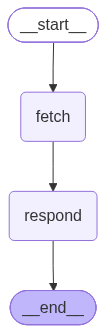

In [13]:
builder = StateGraph(Lookup)
builder.add_node("fetch", fetch)
builder.add_node("respond", respond)
builder.add_edge(START, "fetch")
builder.add_edge("fetch", "respond")
builder.add_edge("respond", END)
lookup = builder.compile()

print(lookup.invoke({"order_id": "ORD-5002"})["reply"])
draw(lookup)

`draw` renders the picture through `draw_mermaid_png()`, which sends the diagram text to the
mermaid.ink web service, so it needs internet (it is free and is not a model call). Offline, `draw`
falls back to `draw_mermaid()`, the same diagram as mermaid text. That text is what v7 commits, in
`workflows/inbox/diagram.md`, so a change in the wiring shows up in a diff.

`invoke` returns the final state. `stream(..., stream_mode="updates")` yields each node's update as it
happens, which is the first time you can *watch* a graph run:

In [14]:
for update in lookup.stream({"order_id": "ORD-5002"}, stream_mode="updates"):
    print(update)

{'fetch': {'order': {'order_id': 'ORD-5002', 'customer_id': 'C-1001', 'items': [{'sku': 'SKU-300', 'name': 'BrewMaster Electric Kettle', 'qty': 2, 'unit_price': 49.0}], 'total': 98.0, 'status': 'processing', 'order_date': '2026-08-01', 'delivered_date': None}}}
{'respond': {'reply': 'ORD-5002 is processing (ordered 2026-08-01).'}}


One dict per step, keyed by the node that produced it, holding only what that node returned. Session
11 uses the other stream modes; session 15 turns this stream into the events a web UI renders.

**Docs:** [Graph API](https://docs.langchain.com/oss/python/langgraph/graph-api) ·
[Streaming](https://docs.langchain.com/oss/python/langgraph/streaming)

## 8. Conditional edges and `Command`

A fixed edge always goes to the same node. A **conditional edge** calls a function, the *router*, and
goes wherever it says. The router's only job is choosing: it reads state, returns a node name, and
does no work. Keep it that cheap. Here session 3's triage decides (the same call, unchanged), and the
router just reads its `category`:

In [20]:
from schemas import TriageResult     # noqa: E402
from triage import triage            # noqa: E402
from utils import load_inbox         # noqa: E402

TICKETS = {t.id: t for t in load_inbox()}


class Routed(TypedDict, total=False):
    ticket: object
    triage: TriageResult
    desk: str


def triage_step(state: Routed) -> dict:
    result, _usage = triage(model, state["ticket"])
    return {"triage": result}


def route(state: Routed) -> str:
    """Zero model calls: a lookup on what triage already decided."""
    if state["triage"].category in ("refund", "billing"):
        return "billing"
    if state["triage"].category in ("return", "warranty"):
        return "policy"
    return "orders"


def desk(name):
    return lambda state: {"desk": name}       # stand-ins: the real desks arrive in section 12


builder = StateGraph(Routed)
builder.add_node("triage", triage_step)
for name in ("orders", "billing", "policy"):
    builder.add_node(name, desk(name))
    builder.add_edge(name, END)
builder.add_edge(START, "triage")
builder.add_conditional_edges("triage", route, ["orders", "billing", "policy"])
routed = builder.compile()

for tid in ("TCK-001", "TCK-002", "TCK-005"):
    out = routed.invoke({"ticket": TICKETS[tid]})
    print(f"{tid}  {out['triage'].category:<13} -> {out['desk']} desk")

TCK-001  order_status  -> orders desk
TCK-002  complaint     -> orders desk
TCK-005  return        -> policy desk


The list `["orders", "billing", "policy"]` passed to `add_conditional_edges` does not affect routing.
It tells the drawing which nodes the router *can* reach, so the diagram shows the branch.

There is a second way to route. A node can return a `Command`, which updates state **and** names the
next node in one return:

In [21]:
from langgraph.types import Command    # noqa: E402


def triage_and_route(state: Routed) -> Command[Literal["orders", "billing", "policy"]]:
    result, _usage = triage(model, state["ticket"])
    return Command(update={"triage": result}, goto=route({"triage": result}))


builder = StateGraph(Routed)
builder.add_node("triage", triage_and_route)
for name in ("orders", "billing", "policy"):
    builder.add_node(name, desk(name))
    builder.add_edge(name, END)
builder.add_edge(START, "triage")              # no conditional edge: the node routes itself
print(builder.compile().invoke({"ticket": TICKETS["TCK-005"]})["desk"])

policy


The return type `Command[Literal[...]]` is not decoration. It is how LangGraph learns which nodes this
one can jump to, for validation and for the drawing.

| Use | When |
|---|---|
| conditional edge + router | the route is a pure function of state. The router can be tested alone, and the node stays ignorant of the graph |
| `Command` from the node | the node doing the work already knows where to go next, e.g. it hit an error and must escalate |

**Docs:** [Graph API: conditional edges, Command](https://docs.langchain.com/oss/python/langgraph/graph-api)

## 9. Build the agent loop by hand

Section 4 showed that `create_agent` is a graph whose core is `model ⇄ tools`. Build that core
yourself. It is three pieces:

1. an `llm_call` node: the model, with tools bound, reads the messages and replies;
2. a `tools` node: runs whatever tool calls the reply contains;
3. a router, `should_continue`: if the last message asked for tools go to `tools`, otherwise stop.

Then one edge from `tools` back to `llm_call`, and that edge is the loop.

In [23]:
from langchain.messages import SystemMessage      # noqa: E402
from langgraph.graph import MessagesState         # noqa: E402
from langgraph.prebuilt import ToolNode           # noqa: E402

from tools import get_shipment                    # noqa: E402

LOOP_TOOLS = [get_order, get_shipment]
llm_with_tools = model.bind_tools(LOOP_TOOLS)


def llm_call(state: MessagesState) -> dict:
    system = SystemMessage("You answer ShopWise order questions using the tools. Be brief.")
    return {"messages": [llm_with_tools.invoke([system, *state["messages"]])]}


def should_continue(state: MessagesState) -> Literal["tools", "__end__"]:
    return "tools" if state["messages"][-1].tool_calls else END


builder = StateGraph(MessagesState)
builder.add_node("llm_call", llm_call)
builder.add_node("tools", ToolNode(LOOP_TOOLS))
builder.add_edge(START, "llm_call")
builder.add_conditional_edges("llm_call", should_continue)
builder.add_edge("tools", "llm_call")          # the loop
loop = builder.compile()

for update in loop.stream({"messages": [HumanMessage("what is in my order ORD-5003 and Where is it?")]}, stream_mode="updates"):
    for node, delta in update.items():
        msg = delta["messages"][-1]
        if node == "tools":
            print(f"tools     {msg.name} returned {msg.text[:110]}")
        else:
            print(f"llm_call  {msg.tool_calls or msg.text[:200]}")

llm_call  [{'name': 'get_order', 'args': {'order_id': 'ORD-5003'}, 'id': 'chatcmpl-tool-dc88622d559b4ea9b75d9a4fe33eb718', 'type': 'tool_call'}]
tools     get_order returned {"order_id": "ORD-5003", "customer_id": "C-1002", "items": [{"sku": "SKU-200", "name": "PulseFit Smartwatch", 
llm_call  [{'name': 'get_shipment', 'args': {'order_id': 'ORD-5003'}, 'id': 'chatcmpl-tool-e4b0f0d036554c539fe505ef817f18f7', 'type': 'tool_call'}]
tools     get_shipment returned {"order_id": "ORD-5003", "carrier": "SwiftEx", "tracking_id": "SW-88231", "status": "in_transit", "eta": "2026
llm_call  • **Order ORD‑5003 contents**  
  • PulseFit Smartwatch – 1 × $199

• **Shipping status**  
  • Carrier: SwiftEx  
  • Tracking ID: SW‑88231  
  • Current status: In transit  
  • Estimated delivery: 


`llm_call` asked for tools, `tools` ran them, `llm_call` read the results and answered, and the router
ended the run. That is session 5's manual agent loop, drawn as a graph.

`ToolNode` is the prebuilt `tools` node: it runs each requested call and wraps every result in a
`ToolMessage` with the right `tool_call_id`. `langgraph.prebuilt` also has `tools_condition`, a
ready-made `should_continue`. The current docs write the router by hand, as above, because it is two
lines and you usually want to change it.

<img src="figures/agent-loop.png" width="900"
     alt="The agent loop, built by hand. Start goes to an llm_call node holding the bound tools. A
     router, should_continue, checks whether the last message asked for tools: if yes, to the tools
     node, which runs them and loops back to llm_call; if no, to the end. A recursion_limit caps the
     loop. A side panel shows that create_agent is this same graph, with a model node and a tools
     node, plus middleware slots, response_format and a context schema.">

**What `create_agent` adds on top** of these lines: middleware hooks before and after every step (your
session 7 rails), `response_format` for structured output, `context_schema` for who is calling, and a
consistent way to handle tool errors. Notice what the hand-built loop does *not* have: no
`authorize`, no limits. It would look up anyone's order. Those rails are worth keeping, which is why
v7's desks are `create_agent`s and not hand-built loops.

**The loop's ceiling.** A loop with no exit runs until something stops it, and that something is
`recursion_limit`: the most steps one run may take. Set it per call:

In [24]:
from langgraph.errors import GraphRecursionError    # noqa: E402

try:
    loop.invoke({"messages": [HumanMessage("Where is ORD-5003?")]}, {"recursion_limit": 2})
except GraphRecursionError as err:
    print(str(err).splitlines()[0])

Recursion limit of 2 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.


Two steps were not enough for llm_call → tools → llm_call. Set the limit yourself, and don't trust any
default you read in a tutorial: they disagree (25, 1,000, 10,000), and at free-tier speeds a runaway
loop spends your quota long before reaching any of them. In v6 the `ModelCallLimitMiddleware` rail is
the real fuse, and the recursion limit is a backstop.

**Docs:** [Workflows and agents: agents](https://docs.langchain.com/oss/python/langgraph/workflows-agents)

## 10. See it run: LangGraph Studio, once

Printing stream updates works, but for a graph with branches it helps to *watch* it. **LangGraph
Studio** is a visual debugger: it draws your graph, runs it, highlights each node as it fires, and lets
you open the state at every step. It is a tool for while you build. LangSmith (session 4) remains the
tool for operating.

v7 ships the two files Studio needs:

| File | What it says |
|---|---|
| `langgraph.json` | which graphs exist (`inbox`, `policy`), where the dependencies are, where `.env` is |
| `studio.py` | the two compiled graphs, as module-level variables `langgraph.json` can name |

From a terminal, in `session-10/project/`:

```bash
uv run --with "langgraph-cli[inmem]" langgraph dev
```

`--with` adds the CLI for that one command and leaves `pyproject.toml` alone. It prints a URL like
`https://smith.langchain.com/studio/?baseUrl=http://127.0.0.1:2024`. Open it (it uses your LangSmith
login), choose `inbox`, and paste a ticket as the input:

```json
{"ticket": {"id": "TCK-M01", "from": "ayesha@example.com", "received": "2026-08-09",
            "subject": "three things, sorry", "body": "My two BrewMaster kettles (ORD-5002) ..."}}
```

Three things worth doing once: watch `split` fan out to several desks at the same time; click a desk
node and read the `findings` it appended; switch to the `policy` graph and watch a question go round
the corrective loop (set `SHOPWISE_RAG_GRADE=true` first).

Two gotchas. The server holds the knowledge base's folder, so close this notebook's kernel first
(embedded Qdrant allows one process at a time). Studio starts runs without a logged-in customer, so
the inbox's nodes fall back to the ticket's sender (`who()` in `workflows/inbox/nodes.py`), and the
authorize rail still holds.

**Docs:** [Run a local server](https://docs.langchain.com/oss/python/langgraph/local-server) ·
[Studio](https://docs.langchain.com/langsmith/studio)

---
# Part B: Five workflow patterns

Five shapes cover most production AI workflows. Each one gets a ShopWise problem it actually solves.

<img src="figures/five-patterns.png" width="900"
     alt="The five workflow patterns on one page, each a small diagram with its ShopWise use. Chaining
     with a gate: draft, tone check, then end or revise. Routing: a category picks a desk with its own
     tools. Parallel: RAG-Fusion searches four phrasings in one step and fuses the ranked lists.
     Orchestrator-worker: split sends one worker per sub-issue, as many as the ticket needs.
     Evaluator-optimizer: retrieve, grade, then generate or rewrite and retry, with a cap.">

## 11. Prompt chaining, with a gate

**Chaining** splits one task into calls in sequence, each working on the last one's output. Each call
does less, so each is easier to get right and easier to check. A **gate** is a conditional edge
between them that can stop the line or send the work back.

ShopWise problem: replies to angry customers. TCK-003 is in capitals and threatening a public post.
Draft a reply, check it against the support desk's rules, and revise once if it fails.

In [ ]:
from pydantic import BaseModel, Field    # noqa: E402

from utils import ask_json               # noqa: E402


class ToneCheck(BaseModel):
    problems: list[str] = Field(description="Each rule the draft breaks, quoted briefly. Empty if none.")
    ok: bool = Field(description="True only if problems is empty.")


RULES = """ShopWise reply rules:
1. Never promise a delivery date, a refund or compensation.
2. Apologise once, for the actual failure, not for the customer's feelings.
3. Say what happens next and who does it.
4. Under 120 words."""


class Reply(TypedDict, total=False):
    ticket: object
    draft: str
    check: ToneCheck
    revised: bool


def draft(state: Reply) -> dict:
    ask = f"Write ShopWise's reply to this ticket. Plain text.\n{state['ticket'].as_block()}"
    return {"draft": model.invoke(ask).text}


def tone_check(state: Reply) -> dict:
    ask = f"{RULES}\n\nCheck this reply against the rules:\n{state['draft']}"
    check, _usage = ask_json(model, ToneCheck, [("human", ask)])
    return {"check": check}


def revise(state: Reply) -> dict:
    ask = (f"{RULES}\n\nRewrite this reply to fix these problems: {state['check'].problems}\n\n"
           f"{state['draft']}")
    return {"draft": model.invoke(ask).text, "revised": True}


def gate(state: Reply) -> str:
    if state["check"].ok or state.get("revised"):      # revise at most once
        return END
    return "revise"


builder = StateGraph(Reply)
builder.add_node("draft", draft)
builder.add_node("tone_check", tone_check)
builder.add_node("revise", revise)
builder.add_edge(START, "draft")
builder.add_edge("draft", "tone_check")
builder.add_conditional_edges("tone_check", gate, ["revise", END])
builder.add_edge("revise", "tone_check")
chain = builder.compile()

final = {}
for update in chain.stream({"ticket": TICKETS["TCK-003"]}, stream_mode="updates"):
    for node, delta in update.items():
        final |= delta
        if node == "tone_check":
            print(f"tone_check  ok={delta['check'].ok}  {delta['check'].problems}")
        else:
            print(f"{node:11} {len(delta['draft'].split())} words")
print("\n" + final["draft"])

<!-- revise after execution: did the first draft fail, and did the final one break a rule anyway? -->
Read the path first: did the first draft pass, or did the checker name a problem and send it to
`revise`? Then read the final reply as the rules' author would. A common result is a reply that passed
the gate and still says something like "your kettles will ship today". Nothing looked that up:
ORD-5002 is still *processing*, and rule 1 forbids promising dates.

A gate is only as good as its checker, and a model checking a model is still a model. Use model gates
for what models judge well: tone, clarity, whether a reply answers the question. A rule about money or
dates belongs in code (session 3's validator on `TriageResult`) or with a person (session 11).

Two details carry the pattern. The checker returns **structure** (`ok`, `problems`), so the gate is a
plain `if` and the revision is told exactly what to fix. And `revised` is a **cap**: a gate that can
send work back needs a way out, or a stubborn checker becomes an infinite bill.

**Docs:** [Workflows and agents: prompt chaining](https://docs.langchain.com/oss/python/langgraph/workflows-agents)

## 12. Routing to desks with scoped tools

Section 8's router sent tickets to stand-ins. In v7 the desks are real, and the point of routing is
what each desk is *allowed* to do. v6's agent held all eight tools for every question. v7's desks
each hold only what their job needs:

In [ ]:
from workflows.inbox.nodes import DESK_FOR, DESKS, desk_agent    # noqa: E402

for name, spec in DESKS.items():
    print(f"{name:8} {[t.name for t in spec['tools']]}")
print("policy   (no agent: order facts in code, then the policy graph, section 15)")
print()
show("DESK_FOR", "workflows/inbox/nodes.py")

This is **least privilege by construction**. No desk holds `issue_refund`: v7 never moves money, and
pausing for a manager arrives in session 11. The billing desk cannot look up a shipment, because it
was never given the tool. A prompt saying "only discuss billing" can be argued with. A missing tool
can't.

Each desk is a small `create_agent`, and **an agent is just a node**: it takes something in and returns
something. Ask the billing desk a shipping question:

In [ ]:
billing = desk_agent("billing")
print(type(billing).__name__)
reply = billing.invoke(
    {"messages": [HumanMessage("Customer: Tanvir Ahmed, customer_id C-1002\n"
                               "Order named for this issue: ORD-5003\nIssue: Where is my parcel?")]},
    context=tanvir)
print(tool_path(reply))
print(reply["messages"][-1].text)

<!-- revise after execution: what did billing say it could and couldn't see? -->
It can answer only from what its tools let it see: the order itself, nothing about tracking. That is
the right behaviour for a desk that should never have received the question. Routing, not the desk, is
what makes sure it doesn't.

The desks keep v6's rails: `middleware.desk_middleware()` is the session 7 stack minus two. Refund
approval goes because nothing can issue a refund. Summarization goes because a desk answers one
question and is gone. `authorize` stays, and section 14 needs it.

**Docs:** [Workflows and agents: routing](https://docs.langchain.com/oss/python/langgraph/workflows-agents) ·
[Custom workflow: an agent is a node](https://docs.langchain.com/oss/python/langchain/multi-agent/custom-workflow)

## 13. Parallelization: RAG-Fusion

When steps don't depend on each other, run them at the same time. Give a node several outgoing edges
and every target runs in the **same step** (LangGraph calls it a *super-step*). Give one node several
incoming edges and it waits for that step to finish, then runs once with everything merged.

ShopWise problem: failure 3's vocabulary mismatch. One search for "money back for a gift" lands on
refund-timing passages; the rule lives under "gift cards". **RAG-Fusion** (Rackauckas, 2024) fixes this
by asking the question several ways:

1. **expand**: one structured call writes three rephrasings in the words a policy would use. Code adds
   the customer's original, so a bad expansion can add noise but never remove the original search.
2. **search** each phrasing, all in parallel.
3. **fuse** the ranked lists with **reciprocal-rank fusion** (RRF, Cormack et al., 2009):

$$\text{score}(d) = \sum_{\text{lists } q} \frac{1}{k + \text{rank}_q(d)}, \qquad k = 60$$

then keep the top 4. A chunk ranked well by several phrasings beats one ranked first by only one.

<img src="figures/rag-fusion.png" width="900"
     alt="RAG-Fusion as parallel fan-out and fan-in. A customer question, money back for a gift, goes
     into an expand node that writes three rephrasings; the original is kept. Four searches run side by
     side in one super-step, each returning a ranked list of passages. A fuse node applies
     reciprocal-rank fusion, adding one over sixty plus rank for each list a passage appears in, and
     keeps the top four. The gift-card clause, ranked second or third by three phrasings, beats a
     passage ranked first by only one. Below, the contrast arm HyDE: write a hypothetical policy
     passage and search with that instead.">

First, by hand. Expand the question, search each phrasing, look at the four lists:

In [ ]:
from kb import fusion    # noqa: E402

queries = fusion.expand({"question": GIFT})["queries"]
lists = []
for q in queries:
    docs = rag.search(q)
    lists.append(docs)
    print(f"\n{q}")
    for rank, d in enumerate(docs, start=1):
        print(f"  {rank}. {rag.label(d)}")

In [ ]:
show("rrf", "kb/fusion.py")
print("\nfused top 4:")
for d in fusion.rrf(lists):
    print(f"  {rag.label(d)}")

<!-- revise after execution: where did "2. What cannot be returned" rank in each list, and after fusion? -->
Find `[returns-policy · 2. What cannot be returned]` in each list. Count how many lists it appears in
and at what rank, then check where fusion put it.

Two things about RRF worth saying out loud:

- **It uses ranks, not scores.** Each query has its own cosine scores, and a 0.71 for one query is not
  comparable with a 0.71 for another. A rank means the same thing in every list, so RRF needs no
  normalisation. That is why it is the default way to merge result lists, including hybrid search's
  dense and keyword lists in session 9.
- **k = 60 damps the head.** First place is worth 1/61 and tenth place 1/70. Being found by several
  phrasings matters more than winning any one.

Now as a graph. The number of phrasings is fixed here (the original plus three), so the fan-out can be
drawn with **static edges**: four search nodes, all wired from `expand`, all wired into `fuse`. Their
shared key `ranked` needs a reducer, which is section 6 again.

In [ ]:
from langchain_core.documents import Document    # noqa: E402
from kb.rag import generate                      # noqa: E402

N = settings.FUSION_QUERIES + 1


class Fusion(TypedDict, total=False):
    question: str
    queries: list[str]
    ranked: Annotated[list[list[Document]], operator.add]
    documents: list[Document]
    answer: str


def searcher(i):
    def search_node(state: Fusion) -> dict:
        return {"ranked": [rag.search(state["queries"][i])]}
    return search_node


def fuse_lists(state: Fusion) -> dict:
    return {"documents": fusion.rrf(state["ranked"])}


def build_fusion_demo(parallel: bool):
    builder = StateGraph(Fusion)
    builder.add_node("expand", fusion.expand)
    builder.add_node("fuse", fuse_lists)
    builder.add_node("generate", generate)            # session 9's, unchanged
    names = [f"search_{i}" for i in range(N)]
    for i, name in enumerate(names):
        builder.add_node(name, searcher(i))
    builder.add_edge(START, "expand")
    if parallel:
        for name in names:
            builder.add_edge("expand", name)          # fan out: one super-step
            builder.add_edge(name, "fuse")            # fan in: fuse waits for all four
    else:
        for a, b in zip(["expand", *names], [*names, "fuse"]):
            builder.add_edge(a, b)                    # one after another
    builder.add_edge("fuse", "generate")
    builder.add_edge("generate", END)
    return builder.compile()


for parallel in (False, True):
    started = time.perf_counter()
    out = build_fusion_demo(parallel).invoke({"question": GIFT})
    print(f"{'parallel' if parallel else 'sequential':10} {time.perf_counter() - started:5.1f}s")
print(f"\nretrieved {[rag.label(d) for d in out['documents']]}\n\n{out['answer']}")

<!-- revise after execution: report the two timings and whether the answer now cites the gift-card clause -->
Same work, less wall-clock time. Most of each search's time is the network call that embeds the
query, and four of those can wait at the same time. (Both runs also pay for `expand` and `generate`,
which run in sequence either way, so the saving is smaller than four to one.)

Use parallel branches only for steps that really are independent. If the second search needed the
first one's answer, putting them side by side would not make it faster. It would make it wrong.

**The project version uses `Send`.** `kb/fusion.py` fans out with one `Send` per query instead of
four drawn edges, because the number of phrasings is a setting (`FUSION_QUERIES`), not a constant.
`Send` is the next section's subject. Read `fusion.fan_out` after it.

**The contrast arm: HyDE.** Hypothetical Document Embeddings (Gao et al., 2022) attack the same
mismatch from the other side. Instead of more questions, write a *fake answer*: a short passage in
policy style. Embed that and search with it, because a fake answer often sits nearer the real answer in
embedding space than a question does. It may be factually wrong, and that doesn't matter, because
nobody reads it:

In [ ]:
out = fusion.hyde({"question": GIFT})
print(f"searched with: {out['hypothesis']}\n")
for d in out["documents"]:
    print(f"  {rag.label(d)}")

| | RAG-Fusion | HyDE |
|---|---|---|
| Extra model calls per question | 1 (expand) | 1 (the fake passage) |
| Extra searches | 3 | 0 |
| Bet it makes | one of several phrasings matches the policy's words | a policy-shaped passage embeds near the real policy |
| Fails when | every phrasing shares the same blind spot | the model's guess at the policy is in the wrong topic entirely |

Both techniques sound convincing, and so does every technique on a blog. On ShopWise's corpus, does
either one move the scorecard? Section 16 measures it. Expect one to help and the other to cost a call
without helping, and keep only what moved.

**Docs:** [Workflows and agents: parallelization](https://docs.langchain.com/oss/python/langgraph/workflows-agents) ·
RAG-Fusion: [arXiv 2402.03367](https://arxiv.org/abs/2402.03367) ·
RRF: [Cormack et al. 2009](https://cormack.uwaterloo.ca/cormacksigir09-rrf.pdf) ·
HyDE: [arXiv 2212.10496](https://arxiv.org/abs/2212.10496)

## 14. Orchestrator-worker with `Send`

Section 13's fan-out had a fixed width: four edges, four branches, drawn before the graph runs. A
multi-issue ticket can't be drawn in advance. TCK-M03 has two issues and TCK-M04 has four, and the
next one might have one.

The **orchestrator-worker** pattern decides the width at run time. An orchestrator node, `split`,
breaks the work into pieces. Then a router returns a **list of `Send` objects**, one per piece, and
LangGraph starts that many workers in the same super-step.

<img src="figures/send-fanout.png" width="900"
     alt="Orchestrator-worker with Send, on the opening ticket. Ayesha's email asks three things. The
     split node returns three sub-issues, each with a category: order_status, refund, warranty. A dict
     lookup sends each one to its desk with zero model calls: orders, billing and policy run in the
     same step, in parallel. Their findings append into one list through the reducer, and compose
     writes one reply that answers all three in order.">

First the orchestrator alone. `split` is one structured-output call returning a list of `SubIssue`s
(in `schemas.py`). Each is the customer's question, restated, with its own category:

In [ ]:
from workflows.inbox.nodes import split    # noqa: E402

m01 = MULTI["TCK-M01"]
for sub in split({"ticket": m01})["sub_issues"]:
    print(f"[{sub.category:<12}] order={sub.order_id}  {sub.question}")

Then the router that turns them into workers:

In [ ]:
show("route_sub_issues", "workflows/inbox/nodes.py")

`Send(node, payload)` means "run this node with this payload". Three things about it catch everyone
the first time:

| Fact | Consequence in v7 |
|---|---|
| The target node receives **only the payload**, not the graph's state | desks are typed `DeskTask` (ticket, sub-issue, position), not `InboxState` |
| Several `Send`s to the **same** node run as separate, parallel calls | TCK-M02's two policy questions run side by side |
| Workers write back through the state, so the key they share needs a reducer | `findings: Annotated[list[dict], operator.add]` |

And one consequence of the reducer: findings are appended in whatever order LangGraph applies the
writes, which says nothing about the order the customer asked in. `compose` sorts by `position`
instead of trusting it.

Now the whole v7 graph, on the opening ticket. `answer_ticket` is from `inbox.py` and prints each
node's update as it lands:

In [ ]:
from inbox import answer_ticket            # noqa: E402
from workflows.inbox import build_inbox    # noqa: E402

inbox = build_inbox()
final = answer_ticket(inbox, m01, steps=True)
print("\n" + final["reply"])

The desks report in one step, in whatever order they finish. Then `compose` runs once. Now the
ticket that defeated v6:

In [ ]:
final = answer_ticket(inbox, m04, steps=True)
print("\n" + final["reply"])

<!-- revise after execution: what did each desk say about the kettle and the double charge? -->
Four sub-issues, four desks, one step. Check the two that went wrong in section 2. The kettle went to
the general desk, which has a context and a tool budget of its own and `get_product` that now matches
"BrewMaster kettle": it should report the kettle out of stock. The double charge reached billing.
Billing can see the order's total but not card payments, so the honest answer is that a manager will
review it, and that is what a desk with no money tools should say.

Last, TCK-M03. Tanvir asks about his own order and about his friend Ayesha's refund. The sender became
the `Customer` context, and the billing desk runs inside `authorize`:

In [ ]:
final = answer_ticket(inbox, MULTI["TCK-M03"], steps=True)
print("\n" + final["reply"])

<!-- revise after execution: confirm the reply refused to discuss ORD-5001 -->
The rail holds inside the graph. When the billing desk asks for ORD-5001, `authorize` sees it belongs
to C-1001 and returns "not authorised", and the reply should discuss only Tanvir's own order.

One more guarantee is in that reply's path. `compose_prompt` says the only square brackets allowed are
citation labels, and models still sometimes write `[ORD-5001]` after "I cannot discuss that". To a
customer that looks like a source. `compose` deletes every bracket that isn't a citation
(`NOT_A_CITATION` in `workflows/inbox/nodes.py`). The prompt asks, and the code makes sure.

**Docs:** [Graph API: Send](https://docs.langchain.com/oss/python/langgraph/graph-api) ·
[Workflows and agents: orchestrator-worker](https://docs.langchain.com/oss/python/langgraph/workflows-agents)

## 15. Evaluator-optimizer: the policy desk

The fifth pattern pairs a step with a check: one call produces, another evaluates, and a failed
evaluation sends the work back. The policy desk uses it. First, though, it fixes section 2's first
failure, and that fix doesn't involve a model.

**Facts first, in code.** "Can I still return it?" needs a rule *and* the order's delivery date. v6
left the lookup to the agent's judgement. v7's policy desk does it in Python, every time, before it
asks about the rule:

In [ ]:
from workflows.inbox.nodes import order_facts    # noqa: E402

print(json.dumps(order_facts("ORD-5004", as_of="2026-08-10", customer=priya), indent=1))
print(order_facts("ORD-5004", as_of="2026-08-10", customer=tanvir))

Three details in those few lines:

- `days_since_delivery` is **counted in code**, from the ticket's received date. Models are unreliable
  at date arithmetic, and a model with no clock will happily invent today's date.
- Calling a tool's `.invoke` directly **goes around the agent's middleware**, so `authorize` does not
  run. `order_facts` applies the same check itself, with the same `owner_of` function, and Tanvir gets
  nothing about Priya's order. If a code path skips the rails, it has to carry the rule itself.
- The desk returns the facts and the cited rule **separately**, as raw data. `compose` is the one node
  that joins "delivered 95 days ago" with "30 days".

**Then the rule, with a check on the search.** The rule comes from session 9's RAG, rebuilt as a graph
in `workflows/corrective_rag/`. `retrieve` and `generate` are added as nodes **without a change**, as
session 9 promised: they took a dict and returned a dict, which is all a node is. Two nodes are new.
`grade` asks whether the passages actually hold the answer, and `rewrite` writes a better search query
when they don't.

<img src="figures/corrective-rag.png" width="900"
     alt="Corrective RAG. A loop: retrieve, then grade the passages; relevant goes to generate, missed
     goes to rewrite the question and retrieve again, at most two searches; out of attempts goes to
     generate, where the grounding contract refuses and hands off to a person. retrieve and generate
     are session 9's functions, unchanged. A side panel shows that the search box can be swapped for
     RAG-Fusion or HyDE, each behind its own switch.">

In [ ]:
from workflows.corrective_rag import build_corrective    # noqa: E402

show("after_grade", "workflows/corrective_rag/nodes.py")
draw(build_corrective(grade=True, fusion=False, hyde=False))

The retry cap lives in state as `attempts`. **A cycle with no exit is a bill with no ceiling**, and the
router reads `attempts` like any other key. Out of attempts, it goes to `generate` anyway, and the
grounding contract from session 9 refuses with its fixed sentence and a promise that a person will
follow up. That is the right answer to a question the documents don't cover, never a guess.

The policy desk *calls* this graph rather than having its nodes added to the inbox graph. Under `Send`
only the first node of a branch receives the payload, and two parallel policy questions would both
write `documents` in the same step. Session 12 names this pattern: a **subgraph**.

`build_corrective` takes three switches. `grade` adds the loop; `fusion` or `hyde` replaces the
`retrieve` box with section 13's nodes. Every combination is one graph, built from the same parts.

Watch the loop work on one of session 9's gold questions, with retrieval starved to one passage
(`k=1`) so that a miss is likely:

In [ ]:
QUESTION = "Does the TrailPack backpack come with a warranty?"
for grade_on in (False, True):
    print(f"── grading {'on' if grade_on else 'off'} ──")
    graph = build_corrective(grade=grade_on, fusion=False, hyde=False)
    for update in graph.stream({"question": QUESTION, "k": 1}, stream_mode="updates"):
        for node, delta in update.items():
            if node == "retrieve":
                print(f"  retrieve  {[d.metadata['section'][:45] for d in delta['documents']]}")
            elif node == "generate":
                print(f"  generate  {delta['answer'][:160]}")
            else:
                print(f"  {node:9} {delta}")

<!-- revise after execution: describe what each run retrieved and answered -->
Compare the two runs. With one passage, the first search can return a warranty passage that is about
*claims* rather than *which products have cover*. Without grading, `generate` does the right thing with
what it has, which is to refuse. With grading, the grader should say "not relevant", the rewrite asks a
sharper question, and the second search should find the coverage table. If the first search already
found the right passage, both runs answer, and the loop added a call for nothing. That is also the
lesson.

**Docs:** [Build a custom RAG agent](https://docs.langchain.com/oss/python/langgraph/agentic-rag) ·
[Workflows and agents: evaluator-optimizer](https://docs.langchain.com/oss/python/langgraph/workflows-agents)

## 16. Did it earn its place? The scorecard

Section 13 built two retrieval techniques and section 15 built a third. Each costs model calls on
**every** policy question. One question proves nothing, in either direction. Session 9 left a scorer
that runs all nineteen gold questions, and v7 gives it a `graph` target and two new columns: **calls**
per question and **seconds** per question.

Five arms, one variable at a time against the straight line (session 2's staircase, at system scale):

| Arm | Search | Grading | Expected extra calls |
|---|---|---|---|
| straight | retrieve | off | 0 (generate only: 1 call) |
| fusion | expand → 4 searches → RRF | off | +1 |
| grade | retrieve | on, max 2 searches | +1 to +3 |
| fusion+grade | fused | on | +2 to +5 |
| hyde | fake passage → search | off | +1 |

> **⚠️ Cost: this cell makes real model calls. Each question costs about 10–15 calls across the five arms.**
> **With `LIMIT = 6` (the default here): about 60–90 model calls, a minute or two.**
> **With `LIMIT = None` (all 19 questions): about 190–285 model calls, several minutes.**
> **Every search also makes one Gemini embedding call (free tier).** Run the cheap look first; set
> `LIMIT = None` only when you want the full scorecard for `kb/RAG-DECISIONS.md`.

In [ ]:
from evals import run_eval    # noqa: E402

# ⚠️ COST: about 10–15 model calls per question (five arms), plus one embedding call per search.
#    LIMIT = 6     ->  about 60–90 model calls    (the default: a cheap first look)
#    LIMIT = None  ->  all 19 questions, about 190–285 model calls
LIMIT = 6
rows = run_eval.questions()[:LIMIT]
results = run_eval.compare(rows=rows)
print(f"policy graph · k={settings.RAG_K} · {settings.model_id} · {len(rows)} questions\n")
run_eval.table(results)

Which questions did each arm get wrong? An average hides which questions moved:

In [ ]:
for arm, result in results.items():
    wrong = {r["id"]: run_eval.failures(r) for r in result["rows"] if run_eval.failures(r)}
    print(f"{arm:14} {wrong or 'no failures'}")

<!-- revise after execution: write the verdict from the numbers above, then set the defaults in config.py
     and fill in kb/RAG-DECISIONS.md. Do not stage a win. -->
**How to read it.** For each arm, ask two questions in order:

1. **Did refusal, citation or retrieval rise, with nothing else falling?** Name the question ids that
   moved. One rescued question out of nineteen is a signal worth writing down. It is not, by itself, a
   reason to pay an extra call on every question.
2. **What did it cost?** The `calls/q` and `s/q` columns. A technique that moves no number and adds a
   call is a cost, however good it sounds.

On a small, clean corpus like ShopWise's (seven documents, about seventy chunks), session 9's
`RAG_K=4` straight line already retrieves most gold chunks, so there may be very little left for any
technique to rescue. A corrective loop typically rescues questions at `k=1` and `k=2` and changes
nothing at `k=4`. If your numbers say the same, the right move is: **built, measured, shipped off**, with the switch ready for the day the corpus
grows. Exercise 6 runs the retry-budget staircase that shows where the loop starts to pay.

**Write it down.** Open `project/kb/RAG-DECISIONS.md` and fill in this session's three rows: the
symptom, the technique, its cost, and whether it moved the number *on ShopWise*. Then set each
default in `config.py` to what the table supports. Session 9 did the same with reranking, and sessions
11 and 12 will add rows. A team that can say "we measured it and it didn't pay" makes better decisions
than one that ships every technique a blog recommends.

---
# Part C: The build

## 17. v7: what you built

<img src="figures/v7-architecture.png" width="900"
     alt="The v7 architecture. inbox.py loads a ticket and turns its sender into the Customer runtime
     context. The graph runs triage once on the whole ticket, then split, then sends each sub-issue to
     one of four desks: orders, billing and general are small agents with their own read-only tools,
     and policy fetches the order's facts in code before calling the policy graph, where fusion and
     grading are switches. Compose writes one reply. A side panel says chat.py and agent.py are
     unchanged v6, and nothing in the graph can issue a refund.">

**The first structural move of the course.** Until tonight every module sat flat in `project/`. v7 has
two graphs of its own, so each gets a folder with the same anatomy:

```
before (v6)                    after (v7)
project/                       project/
├── agent.py                   ├── agent.py        (unchanged)
├── chat.py                    ├── chat.py         (unchanged)
├── kb/                        ├── inbox.py        new: the graph's entry point
│   ├── rag.py                 ├── studio.py       new: graphs for LangGraph Studio
│   └── ...                    ├── langgraph.json  new
└── ...                        ├── kb/
                               │   ├── rag.py      (unchanged: its functions are nodes now)
                               │   ├── fusion.py   new: RAG-Fusion, HyDE, RRF
                               │   └── RAG-DECISIONS.md
                               ├── workflows/
                               │   ├── inbox/            state.py · nodes.py · graph.py · diagram.md
                               │   └── corrective_rag/   state.py · nodes.py · graph.py
                               └── report/gather.py   new [ADV]
```

*Why:* two workflows now, so each gets a folder with the same anatomy. `state.py` is what the graph
remembers, `nodes.py` holds the steps, and `graph.py` holds the wiring and one `build_*` function. Once
you have opened one folder, you know where everything is in the next. Later sessions grow the project
towards a production service layout one step at a time, never more than a move or two per session.

| File | Change | Why it is separate |
|---|---|---|
| `workflows/inbox/state.py` | **new**: `InboxState`, `DeskTask` | the state is a design decision, read first |
| `workflows/inbox/nodes.py` | **new**: triage, split, `DESK_FOR`, four desks, `order_facts`, compose | every node, each a plain function |
| `workflows/inbox/graph.py` | **new**: `build_inbox()` | topology in one place |
| `workflows/inbox/diagram.md` | **new**: the graph as mermaid text | committed, so wiring changes show in a diff |
| `workflows/corrective_rag/` | **new**, same three files | session 9's functions as nodes, three switches |
| `kb/fusion.py` | **new**: `expand`, `fan_out`, `search_one`, `fuse`, `hyde`, `rrf` | beside the search it improves |
| `kb/RAG-DECISIONS.md` | **new**: one row per technique, with its cost | decisions with numbers |
| `inbox.py` | **new**: `uv run python inbox.py TCK-M01` | the graph's entry point |
| `studio.py`, `langgraph.json` | **new** | what `langgraph dev` loads |
| `schemas.py` | `SubIssue`, `TicketSplit`, `Rephrasings`, `Grade` | structured output, typed like triage's |
| `prompts.yml` | split, desk, compose, expand, hyde, grade, rewrite, each versioned | one prompt per job a node does |
| `middleware.py` | `desk_middleware()` | session 7's rails for the desks |
| `tools.py` | `get_product` matches every word; its no-match list is `catalogue` | section 2 |
| `config.py` | `RAG_FUSION`, `RAG_HYDE`, `RAG_GRADE`, `RAG_MAX_ATTEMPTS`, `FUSION_QUERIES`, `RRF_K`; 7.0.0 | one switch per technique |
| `evals/run_eval.py` | `--target graph`, `--arms`, calls and seconds | scores every arm |
| `report/gather.py` | **new** [ADV]: the Daily Brief's three gather steps | the exercise builds the rest |

**`chat.py` and `agent.py` did not change, and that's deliberate.** A chat is a conversation with a
logged-in customer. It has to survive restarts and pause while a manager approves a refund. Tonight's
graph can't remember anything or pause for anyone yet, so putting the chat behind it would quietly
drop two things v6 already does. The inbox needs neither, so it went first. Session 11 gives the graph
a checkpointer and `interrupt()`, and then the chat can move.

The opening's three failures, against v7:

| Failure | v7's answer |
|---|---|
| 1. a rule applied without the order's date | `order_facts` runs in code before the rule, every time |
| 2. four issues, one context | `split` + `Send`: one desk per issue |
| 3. weak retrieval nobody checked | fusion and grading, each behind a switch the scorecard sets |

From a terminal, in `project/`. The cell below runs one ticket so the committed output shows it:

In [ ]:
store.close_shared()           # embedded Qdrant: one process at a time
out = subprocess.run([sys.executable, "inbox.py", "TCK-M02", "--steps"], cwd=HERE / "project",
                     capture_output=True, text=True)
print(out.stdout or out.stderr[-2000:])

```bash
uv run python inbox.py --list                     # every ticket, both fixtures
uv run python inbox.py TCK-M01 --steps            # watch each node land
uv run python -m workflows.inbox.graph            # print the topology, rewrite diagram.md
uv run python -m workflows.corrective_rag.graph   # the policy graph, four shapes
uv run python kb/fusion.py "money back for a gift?"
uv run python evals/run_eval.py --target graph --fusion
uv run python evals/run_eval.py --arms --limit 6
uv run --with "langgraph-cli[inmem]" langgraph dev
uv run python report/gather.py                    # [ADV] the brief's facts
```

## 18. Where this leaves us

| v6 | v7 |
|---|---|
| one agent, every tool, order by prompt | desks with scoped tools, order in edges |
| multi-issue ticket: confident wrong answers | `Send` splits it; each issue goes to the right desk |
| a rule applied without the order's date | facts fetched in code, then the rule |
| weak retrieval goes straight to generation | fused, graded, rewritten, retried (capped), when the scorecard says so |
| `create_agent` = magic | `create_agent` = a graph you can draw, rails and all |

> The billing desk can see that ORD-5001 is owed $129 on REF-9001, and the best it can do is promise
> that a manager will look. Nothing in the graph can **stop**, wait for that manager until 9 AM, and
> **wake up exactly where it slept**. And when Tanvir follows up with "and what about the watch?",
> retrieval searches for those five words, with no idea which watch. Next session: checkpoints,
> `interrupt()`, and memory that outlives the ticket.

### 18.1 Interview questions

1. Agent or workflow: who chooses the next step? Give one business reason each one wins.
2. What is a reducer, and what happens when two parallel nodes write the same key without one?
3. Conditional edge or `Command`: when would you use each?
4. Explain reciprocal-rank fusion in two sentences. Why does a corrective-RAG loop need a retry cap?
5. How do you guarantee "look up the order before answering whether it can be returned"
   structurally rather than by prompt?
6. You added a self-correcting loop and the eval didn't move. Do you ship it?

Exercises: `exercises.ipynb`.

---
## Appendix: for afterwards

### A. The SQL-agent A/B: "why LangGraph", ShopWise edition

The cleanest demonstration of section 4 uses SQL. Give `create_agent` four SQL tools (`list_tables`,
`get_schema`, `run_query`, `check_query`) and a prompt saying "always inspect the schema first", over
a SQLite copy of `backend.yml`. Run twenty questions and count how often it skips `get_schema` and
guesses a column name. Then rebuild it as a hand-wired graph where list_tables → get_schema → generate
→ check → run is **structural**. The LangGraph version forces the first two calls with
`tool_choice` and overwrites messages by id to keep the context short.

Build the database with `sqlite3` and three `CREATE TABLE` statements from `shopwise_data`'s dicts (no
new dependency). Follow the two official tutorials side by side:
[the agent](https://docs.langchain.com/oss/python/langchain/sql-agent) and
[the graph](https://docs.langchain.com/oss/python/langgraph/sql-agent). The A/B result, skips per
twenty runs, is a good portfolio line.

### B. The Functional API: the same runtime, written as plain Python

Everything tonight used the **Graph API**: nodes and edges declared, then compiled. LangGraph has a
second way to write the same thing, where control flow is ordinary Python and each step is a `@task`:

In [ ]:
from langgraph.func import entrypoint, task    # noqa: E402


@task
def fetch_order(order_id: str) -> dict:
    return get_order.invoke({"order_id": order_id})


@task
def fetch_shipment(order_id: str) -> dict:
    return get_shipment.invoke({"order_id": order_id})


@entrypoint()
def order_brief(order_id: str) -> str:
    order, shipment = fetch_order(order_id), fetch_shipment(order_id)   # both start at once
    order, shipment = order.result(), shipment.result()
    where = shipment.get("status", "not shipped yet")
    return f"{order['order_id']}: {order['status']}, shipment {where}"


order_brief.invoke("ORD-5003")

Calling a task returns a future, so the two lookups ran in parallel. You get the same checkpointing,
streaming and `interrupt()` as the Graph API. It reads better for a linear pipeline with a loop or
two. The course uses the Graph API because you can draw it, and in sessions 11 and 12 the drawing is
the debugging tool. One mental model is enough.

**Docs:** [Functional API](https://docs.langchain.com/oss/python/langgraph/functional-api)

### C. Self-RAG and adaptive RAG

Both are variations on section 15, and both exist in LangGraph's archived notebooks
(`github.com/langchain-ai/langgraph/tree/main/examples/rag`, marked "archival, no longer updated"):

- **Self-RAG** grades the *answer* as well as the passages: is it grounded, and does it answer the
  question? A failed answer goes back to `generate`, or to `rewrite`. Same loop, one more grader, one
  more cap.
- **Adaptive RAG** routes *before* retrieving: no retrieval for "thanks!", one search for a simple
  rule, the corrective loop for a hard one. A router on the question's type (section 8), choosing
  between three of tonight's shapes.
- **Query decomposition**: "can I return it, and who pays postage?" is two searches. Split before
  `retrieve`, which is `Send` again, one level down.
- **Per-passage grading**: the official tutorial grades the set in one call, as v7 does. Grading each
  passage separately can drop the irrelevant ones before `generate`, at RAG_K calls per search.

### D. `Send` at scale: `max_concurrency` and `defer`

A ticket with forty sub-issues would start forty desks at once and hit your rate limit. Cap it per
call:

In [ ]:
from langgraph.types import Send    # noqa: E402


class Fan(TypedDict, total=False):
    items: list[int]
    done: Annotated[list[int], operator.add]


running, peak = 0, 0


def work(payload: dict) -> dict:
    global running, peak
    running += 1
    peak = max(peak, running)
    time.sleep(0.2)
    running -= 1
    return {"done": [payload["item"]]}


builder = StateGraph(Fan)
builder.add_node("work", work)
builder.add_conditional_edges(START, lambda s: [Send("work", {"item": i}) for i in s["items"]], ["work"])
builder.add_edge("work", END)
fan = builder.compile()

for limit in (None, 2):
    peak = 0
    config = {"max_concurrency": limit} if limit else {}
    fan.invoke({"items": list(range(6))}, config)
    print(f"max_concurrency={limit}: at most {peak} ran at once")

`defer=True` on a node (`add_node("compose", compose, defer=True)`, a keyword on langgraph 1.2's
`add_node`) makes it wait until **every** pending branch has finished, even branches of different
lengths. Without it, a join after one short branch and one long branch can run twice. v7 doesn't need
it, because every desk is one node long. The day a desk becomes two nodes, it will.

**Docs:** [Use the graph API: defer, max_concurrency](https://docs.langchain.com/oss/python/langgraph/use-graph-api)

### E. Pydantic state instead of `TypedDict`

State can be a Pydantic model, and then the graph's **input** is validated:

In [ ]:
class Checked(BaseModel):
    order_id: str = Field(pattern=r"^ORD-\d{4}$")
    reply: str = ""


builder = StateGraph(Checked)
builder.add_node("respond", lambda s: {"reply": f"looking up {s.order_id}"})
builder.add_edge(START, "respond")
builder.add_edge("respond", END)
checked = builder.compile()

print(checked.invoke({"order_id": "ORD-5003"}))
try:
    checked.invoke({"order_id": "order five"})
except Exception as err:
    print(type(err).__name__, str(err).splitlines()[0])

The trade-offs: nodes get attribute access (`s.order_id`), and validation runs on the input to the
graph, not on every node's return. That costs time on every step and catches less than people expect.
v7 uses `TypedDict` and validates where data actually enters: the model's structured output
(`TriageResult`, `TicketSplit`) and the settings.

### F. Case studies

**Feature triage on the spectrum.** Place each ShopWise feature on the workflow ↔ agent line, with one
reason: support chat · daily sales report · refund approval · SEO product descriptions · fraud
flagging. The disagreements are the lesson. (One defensible answer: agent · workflow · workflow with
a human node · chaining with a gate · workflow with a model scoring step and a rule-based threshold.)

**The RAG review meeting, part 1.** A teammate wants to switch on fusion *and* the corrective loop
*and* HyDE "because the blog said so". Answer with section 16's table. Change one variable at a time,
and remember that a technique that doesn't move the number costs calls for nothing. Session 11
continues the meeting.